<a href="https://colab.research.google.com/github/santiagoleguizamon10/TP-labo/blob/fran_pando/NuevomodeloRol3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Influencia de la Localía en el Control del Juego y la Posesión**

¿Existe una influencia estadísticamente significativa de la localía sobre el porcentaje de posesión del balón, o la tenencia responde a la identidad táctica de los equipos al margen del estadio?

En el fútbol se asume que jugar en el propio estadio genera una presión ambiental y territorial que impele al equipo local a tomar el protagonismo del partido. Evaluar esta variable permite cuantificar si la localía altera la tenencia del balón o si es una dimensión neutra ante el modelo de juego de cada club.

In [3]:
# ==============================================================================
# PASO 1: IMPORTACIÓN DE LIBRERÍAS Y CARGA DEL DATASET --------- PASO A ELIMINAR A LA HORA DE JUNTAR CON EL TRABAJO PRINCIPAL ------------
# ==============================================================================
# Justificación: Establece el entorno reproducible en Google Colab e inspecciona
# las variables de posesión de balón y condición de localía.
# Logro: Carga en memoria del DataFrame y verificación de las 194 observaciones.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

url = 'https://raw.githubusercontent.com/santiagoleguizamon10/TP-labo/main/data/Clausura26_tp_labo.csv'
df = pd.read_csv(url)

print("Dimensiones del dataset:", df.shape)
df.head(3)

Dimensiones del dataset: (194, 21)


,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
0,Fecha 1,Club Atlético Belgrano,Rosario Central,2,1,48%,52%,1.50,1.39,13,...,5,3,6,6,10,13,0.0,2.0,0,0
1,Fecha 1,Sarmiento,Argentinos Juniors,2,3,45%,55%,1.50,1.42,12,...,3,5,7,2,15,14,3.0,6.0,0,1
2,Fecha 1,Defensa y Justicia,Aldosivi,1,1,72%,28%,1.06,0.59,15,...,5,3,6,2,9,15,2.0,3.0,0,0


In [4]:
# ==============================================================================
# PASO 2: LIMPIEZA DE DATOS Y CONSTRUCCIÓN DE LA BRECHA TERRITORIAL ------- PASO A REESTRUCTURAR A LA HORA DE JUNTAR CON EL TRABAJO PRINCIPAL -------
# ==============================================================================
# Justificación: Convierte la posesión de texto (%) a flotante numérico y calcula
# la diferencia neta de posesión entre el local y el visitante (Dif_Posesion).
# Logro: Habilita el cálculo de medias, medianas y desviaciones estándar.

# 1. Conversión de tipo de dato (string con % a float)
df['Posesion_L_num'] = df['Posesión de balón (L)'].str.rstrip('%').astype(float)
df['Posesion_V_num'] = df['Posesión de balón (V)'].str.rstrip('%').astype(float)

# 2. Margen de ventaja en la tenencia del local
df['Dif_Posesion'] = df['Posesion_L_num'] - df['Posesion_V_num']

print("Limpieza completada.")
print(f"Posesión Promedio Local: {df['Posesion_L_num'].mean():.2f}%")
print(f"Posesión Promedio Visitante: {df['Posesion_V_num'].mean():.2f}%")

Limpieza completada.
Posesión Promedio Local: 51.05%
Posesión Promedio Visitante: 48.95%


In [5]:
# ==============================================================================
# PASO 3: ANÁLISIS GLOBAL DEL EFECTO CAMPO EN LA POSESIÓN
# ==============================================================================
# Justificación: Evalúa si la condición de local altera el control del balón a nivel
# general en la liga mediante estadísticos descriptivos y una prueba t pareada.
# Logro: Cuantifica el sesgo general (+2.14%) y determina su significatividad.

mediana_L = df['Posesion_L_num'].median()
mediana_V = df['Posesion_V_num'].median()
pct_mayor_50 = (df['Posesion_L_num'] > 50).mean() * 100

t_stat, p_val = stats.ttest_rel(df['Posesion_L_num'], df['Posesion_V_num'])

print(f"Mediana Posesión Local: {mediana_L:.1f}% | Visitante: {mediana_V:.1f}%")
print(f"Porcentaje de partidos donde el local tuvo >50% de posesión: {pct_mayor_50:.1f}%")
print(f"Prueba t para muestras pareadas: t-stat = {t_stat:.4f}, p-value = {p_val:.4f}")

Mediana Posesión Local: 51.0% | Visitante: 49.0%
Porcentaje de partidos donde el local tuvo >50% de posesión: 53.1%
Prueba t para muestras pareadas: t-stat = 1.1816, p-value = 0.2388


In [6]:
# ==============================================================================
# PASO 4: AGREGACIÓN POR CLUB — EL "EFECTO EMPUJE" DE LA LOCALÍA (`groupby`)
# ==============================================================================
# Justificación: Mide cuánto varía la posesión de cada equipo cuando juega de local
# en comparación a cuando juega de visitante (Efecto_Localia_Pos = Pos_L - Pos_V).
# Logro: Aísla la influencia real del estadio del estilo propio del entrenador.

locales = df.groupby('Local')['Posesion_L_num'].agg(['mean', 'count']).rename(columns={'mean': 'Pos_Local_Prom', 'count': 'PJ_L'})
visitantes = df.groupby('Visitante')['Posesion_V_num'].agg(['mean', 'count']).rename(columns={'mean': 'Pos_Visitante_Prom', 'count': 'PJ_V'})

equipos = locales.join(visitantes)
equipos['Efecto_Localia_Pos'] = equipos['Pos_Local_Prom'] - equipos['Pos_Visitante_Prom']
equipos_ordenados = equipos.sort_values(by='Efecto_Localia_Pos', ascending=False)

print("Top 3 Equipos donde la localía MÁS incrementa la posesión:")
print(equipos_ordenados[['Pos_Local_Prom', 'Pos_Visitante_Prom', 'Efecto_Localia_Pos']].head(3))

print("\nTop 3 Equipos donde la localía MENOS influye o es inversa:")
print(equipos_ordenados[['Pos_Local_Prom', 'Pos_Visitante_Prom', 'Efecto_Localia_Pos']].tail(3))

Top 3 Equipos donde la localía MÁS incrementa la posesión:
                           Pos_Local_Prom  Pos_Visitante_Prom  \
Local                                                           
Racing Club                     63.375000           49.000000   
Estudiantes de Río Cuarto       50.571429           37.166667   
CA Independiente                57.833333           45.714286   

                           Efecto_Localia_Pos  
Local                                          
Racing Club                         14.375000  
Estudiantes de Río Cuarto           13.404762  
CA Independiente                    12.119048  

Top 3 Equipos donde la localía MENOS influye o es inversa:
                  Pos_Local_Prom  Pos_Visitante_Prom  Efecto_Localia_Pos
Local                                                                   
Tigre                  46.666667           51.571429           -4.904762
Barracas Central       48.000000           54.000000           -6.000000
Sarmiento              

/tmp/ipykernel_376/4104909092.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


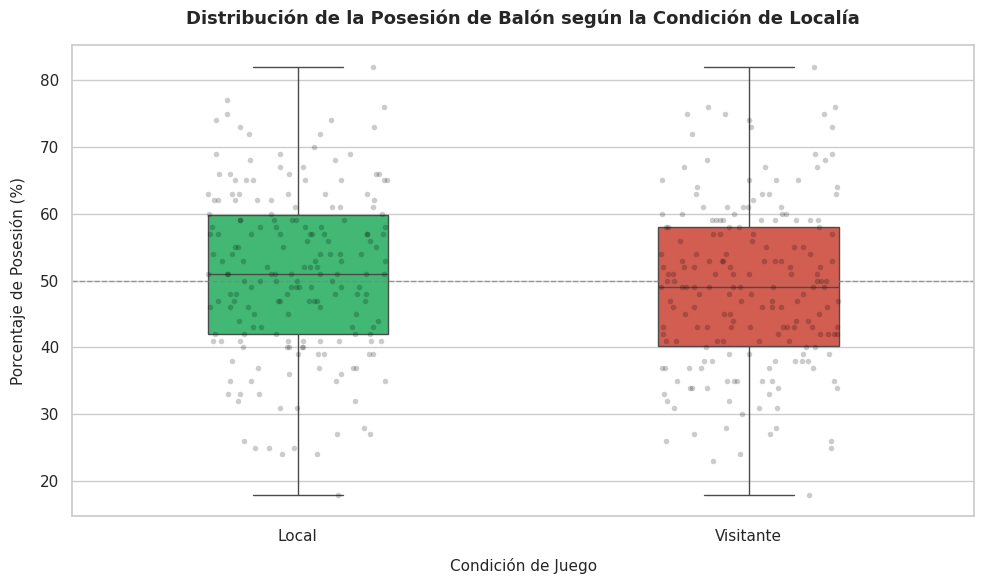

In [7]:
# ==============================================================================
# PASO 5: VISUALIZACIÓN PRINCIPAL (GRÁFICO 3) — BOXPLOT LOCAL VS. VISITANTE
# ==============================================================================
# Justificación: Muestra la distribución comparativa y la dispersión del porcentaje
# de posesión obtenido por los equipos según su condición (Local vs. Visitante).
# Logro: Gráfico normado exportado como 'grafico3_rol3_localia_pura.png'.

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

df_melted = df.melt(value_vars=['Posesion_L_num', 'Posesion_V_num'], var_name='Condición', value_name='Posesión (%)')
df_melted['Condición'] = df_melted['Condición'].map({'Posesion_L_num': 'Local', 'Posesion_V_num': 'Visitante'})

sns.boxplot(
    data=df_melted,
    x='Condición',
    y='Posesión (%)',
    palette=['#2ecc71', '#e74c3c'],
    ax=ax,
    width=0.4
)

sns.stripplot(
    data=df_melted,
    x='Condición',
    y='Posesión (%)',
    color='black',
    alpha=0.2,
    jitter=0.2,
    size=4,
    ax=ax
)

ax.set_title('Distribución de la Posesión de Balón según la Condición de Localía', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Condición de Juego', fontsize=11, labelpad=10)
ax.set_ylabel('Porcentaje de Posesión (%)', fontsize=11, labelpad=10)
ax.axhline(50, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.tight_layout()
plt.savefig('grafico3_rol3_localia_pura.png', dpi=300)
plt.show()

/tmp/ipykernel_376/872033009.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


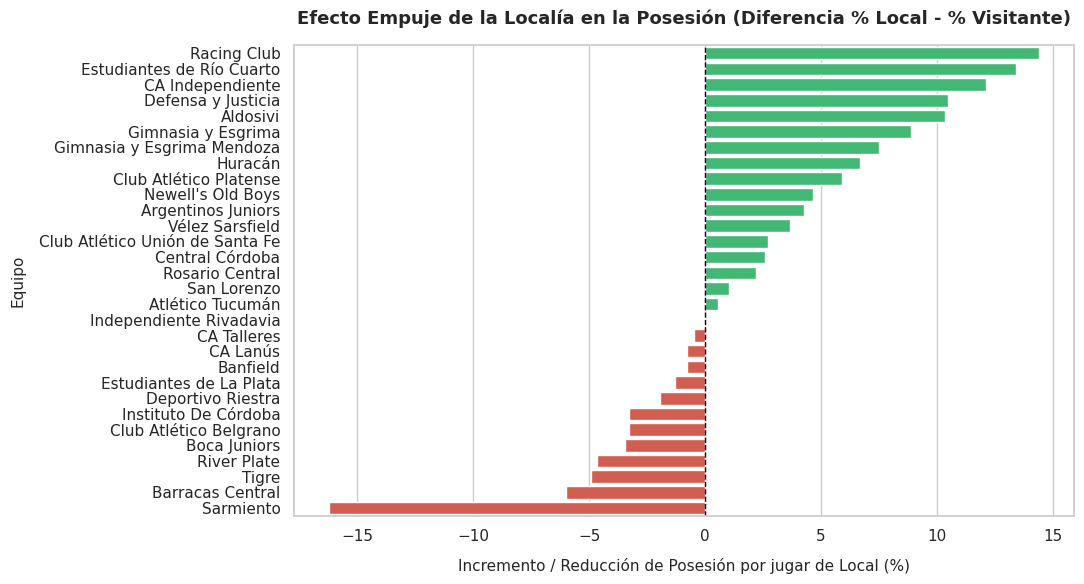

In [12]:
# ==============================================================================
# PASO 6: VISUALIZACIÓN AUXILIAR — RANKING DEL "EFECTO EMPUJE" POR CLUB
# ==============================================================================
# Justificación: Permite visualizar qué instituciones modifican su actitud de juego
# al actuar en casa versus las que mantienen una postura táctica rígida.
# Logro: Gráfico de barras horizontales guardado como 'grafico_auxiliar_efecto_empuje.png'.

top_bottom_efecto = pd.concat([equipos_ordenados.head(15), equipos_ordenados.tail(15)]).reset_index()

fig2, ax2 = plt.subplots(figsize=(11, 6))
colors = ['#2ecc71' if val > 0 else '#e74c3c' for val in top_bottom_efecto['Efecto_Localia_Pos']]

sns.barplot(
    data=top_bottom_efecto,
    x='Efecto_Localia_Pos',
    y='Local',
    palette=colors,
    ax=ax2
)

ax2.set_title('Efecto Empuje de la Localía en la Posesión (Diferencia % Local - % Visitante)', fontsize=13, fontweight='bold', pad=15)
ax2.set_xlabel('Incremento / Reducción de Posesión por jugar de Local (%)', fontsize=11, labelpad=10)
ax2.set_ylabel('Equipo', fontsize=11, labelpad=10)
ax2.axvline(0, color='black', linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig('grafico_auxiliar_efecto_empuje.png', dpi=300)
plt.show()